<a href="https://colab.research.google.com/github/SandhyaSharma1512/2025ae05860-mlops-assignment1/blob/main/notebooks/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 — Data Acquisition and Exploratory Data Analysis

This notebook covers assignment section 1: dataset acquisition, cleaning, missing values, class balance, distributions, and correlations.

**Run from the project root** after installing `requirements.txt`. The data source is the UCI Heart Disease dataset accessed through `ucimlrepo`. This is an educational dataset and the analysis is not for clinical use.


In [11]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()
print(PROJECT_ROOT)

if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from heart_disease.data import download_dataset, prepare_dataset, RAW_PATH, PROCESSED_PATH

print("Project root:", PROJECT_ROOT)


/content/2025ae05860-mlops-assignment1/2025ae05860-mlops-assignment1
Project root: /content/2025ae05860-mlops-assignment1/2025ae05860-mlops-assignment1


In [13]:
# Download if raw data is not present, then create the processed CSV.
if not RAW_PATH.exists():
    download_dataset(RAW_PATH)

processed_path = prepare_dataset(RAW_PATH, PROCESSED_PATH)
print("Raw data:", RAW_PATH)
print("Processed data:", processed_path)


Raw data: /content/2025ae05860-mlops-assignment1/data/raw/heart_disease.csv
Processed data: /content/2025ae05860-mlops-assignment1/data/processed/heart_disease.csv


/content/2025ae05860-mlops-assignment1/src/heart_disease/data.py:33: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  frame[col] = pd.to_numeric(frame[col], errors="ignore")


In [14]:
import pandas as pd
df = pd.read_csv(PROCESSED_PATH)
print("Shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype"))


Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


,dtype
age,int64
sex,int64
cp,int64
trestbps,int64
chol,int64
fbs,int64
restecg,int64
thalach,int64
exang,int64
oldpeak,float64


In [15]:
# Basic quality checks
print("Duplicate rows:", int(df.duplicated().sum()))
missing = df.isna().sum().sort_values(ascending=False)
display(missing.to_frame("missing_count"))
display(df.describe(include="all").T)


Duplicate rows: 0


,missing_count
ca,4
thal,2
cp,0
trestbps,0
age,0
sex,0
fbs,0
chol,0
restecg,0
thalach,0


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


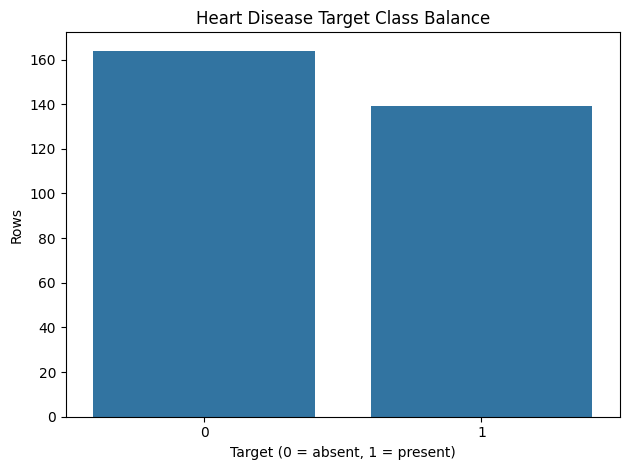

Target proportions:


,proportion
target,
0,0.541254
1,0.458746


In [16]:
# Target balance
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="target")
plt.title("Heart Disease Target Class Balance")
plt.xlabel("Target (0 = absent, 1 = present)")
plt.ylabel("Rows")
plt.tight_layout()
plt.show()

print("Target proportions:")
display(df["target"].value_counts(normalize=True).rename("proportion").to_frame())


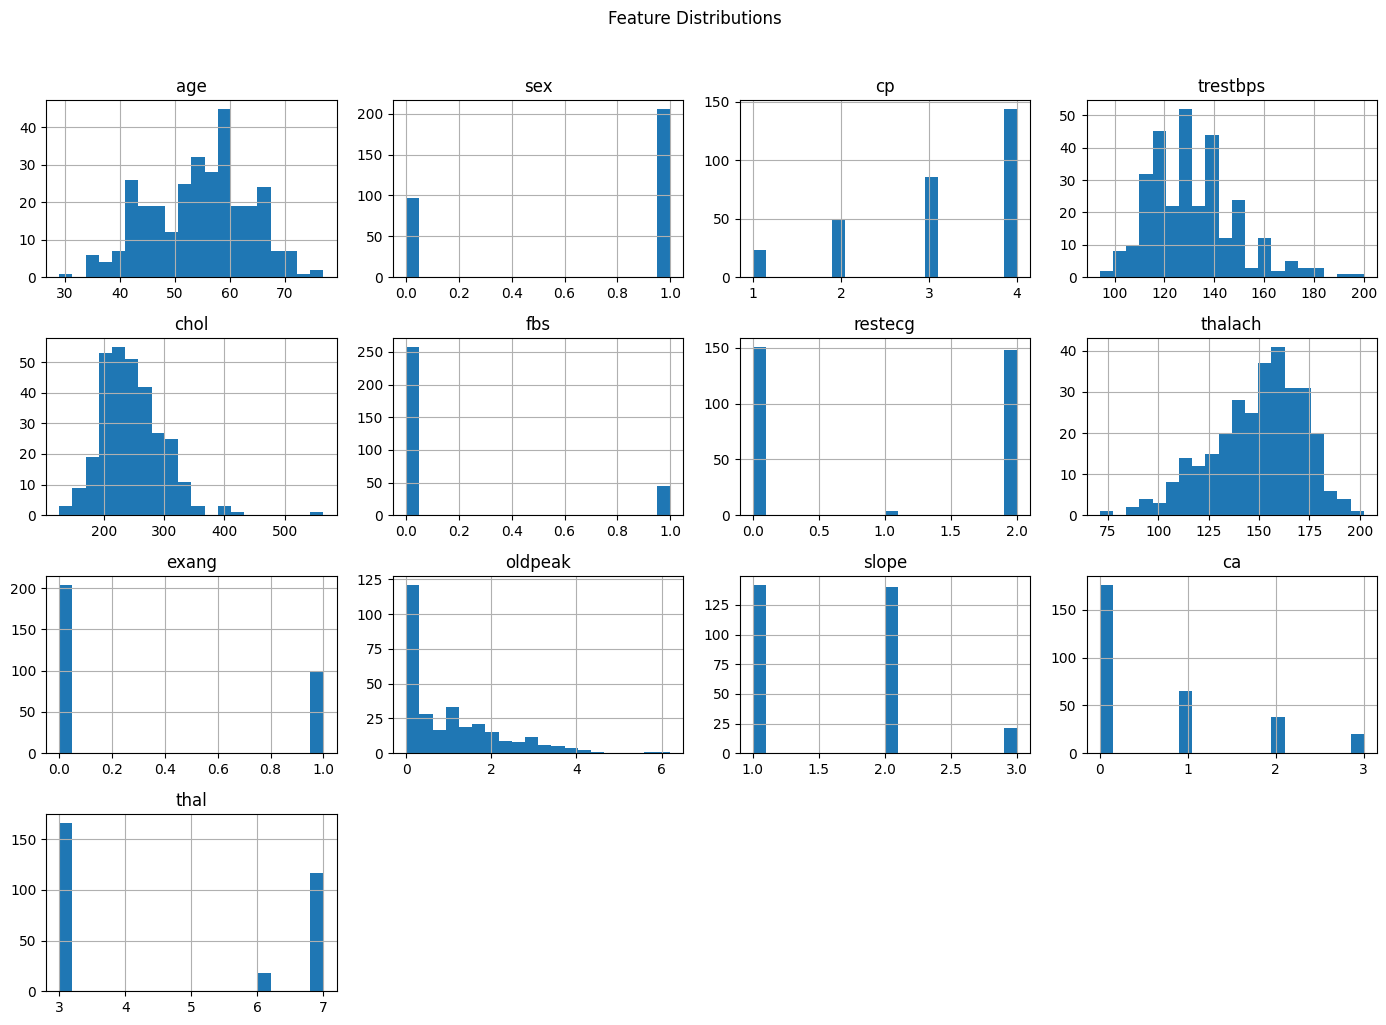

In [17]:
# Histograms of numeric features
numeric_features = [c for c in df.select_dtypes(include="number").columns if c != "target"]
df[numeric_features].hist(figsize=(14, 10), bins=20)
plt.suptitle("Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()


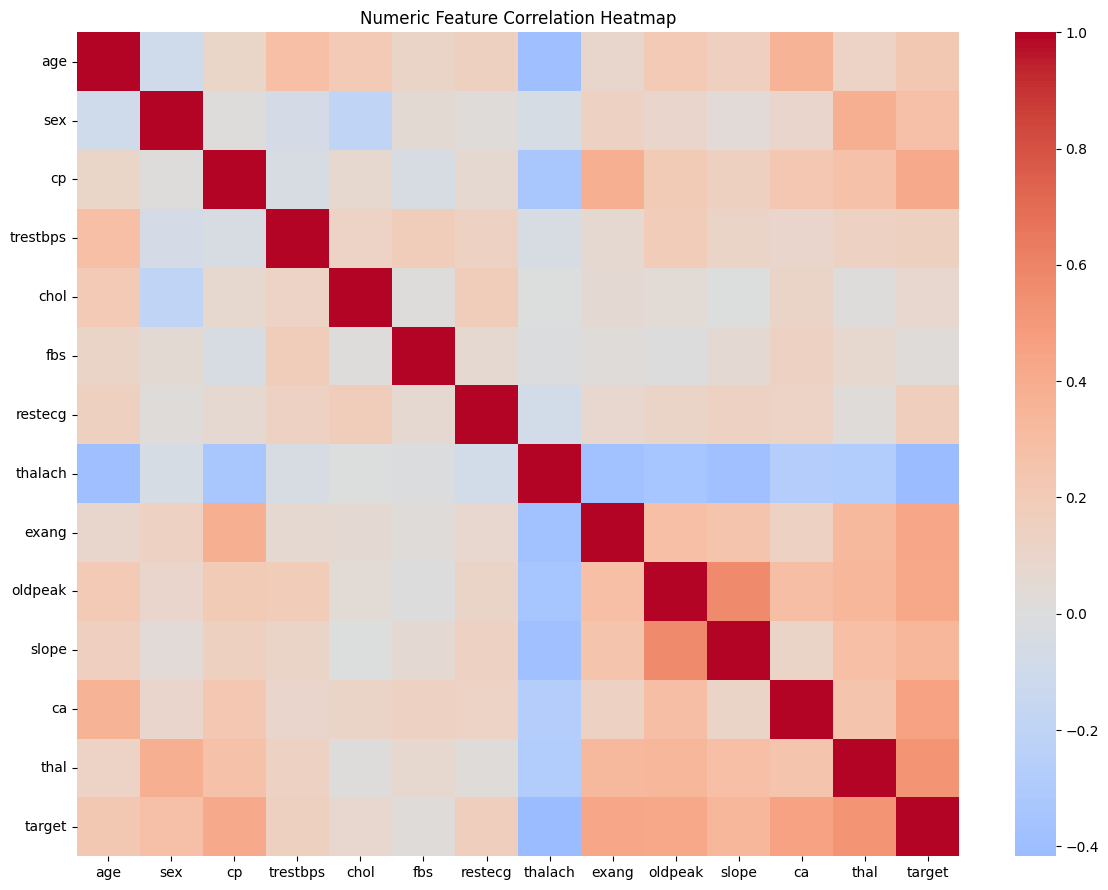

In [18]:
# Correlation heatmap for numeric columns
plt.figure(figsize=(12, 9))
sns.heatmap(df.select_dtypes(include="number").corr(), cmap="coolwarm", center=0)
plt.title("Numeric Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


## Interpretation prompts

Write your own observations before submission:

- Is the target class balanced?
- Which features have the most missing values?
- Which features appear skewed or have outliers?
- Which feature pairs show notable correlation?
- What are the limitations of this dataset and what should not be inferred from correlation?


In [19]:
# Save a compact summary and plots for the report.
from heart_disease.eda import create_eda
summary = create_eda(PROCESSED_PATH, PROJECT_ROOT / "reports" / "eda")
summary


{'rows': 303, 'columns': 14, 'target_balance': {0: 164, 1: 139}}